# 12.4. TFT: трансформер как система

Предыдущие модели решали одну задачу: один ряд, известное прошлое, точечный прогноз. Прикладная задача
выглядит иначе — много рядов, разнотипные признаки, часть которых известна на горизонте, а часть нет,
и нужен интервал, а не одно число.

Temporal Fusion Transformer (Lim et al., 2021) — система, собранная под эту задачу. Внимание в ней есть,
но оно один из компонентов: гейт может закрыть его целиком, и модель останется LSTM с отбором признаков.

Разбираем:
- три типа входов и главный вопрос к признаку — будет ли он известен в момент прогноза;
- устройство: GRN, отбор переменных, LSTM как позиционное кодирование, интерпретируемое внимание;
- TFT на почасовом потреблении Испании, с признаками и без;
- две встроенные интерпретации: важности переменных и внимание как функция лага;
- квантильная голова и проверка интервалов.

In [1]:
import logging
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch
from neuralforecast import NeuralForecast
from neuralforecast.losses.pytorch import MQLoss
from neuralforecast.models import DLinear, PatchTST, TFT
from statsforecast import StatsForecast
from statsforecast.models import SeasonalNaive
from utilsforecast.evaluation import evaluate
from utilsforecast.losses import mae, mape

warnings.simplefilter("ignore")
for name in ["pytorch_lightning", "lightning", "lightning.pytorch", "lightning_fabric"]:
    logging.getLogger(name).setLevel(logging.ERROR)
plt.rcParams["figure.figsize"] = (12, 4)
plt.rcParams["axes.grid"] = True

SEED = 1
ACCELERATOR = "gpu" if torch.cuda.is_available() else "cpu"
TRAINER_KW = dict(accelerator=ACCELERATOR, enable_progress_bar=True, enable_model_summary=False, logger=False)

In [2]:
def score(cv):
    """MAE и MAPE каждой модели, усреднённые по окнам кросс-валидации."""
    models = [c for c in cv.columns if c not in ("unique_id", "ds", "cutoff", "y")]
    res = evaluate(cv, metrics=[mae, mape], models=models)
    return res.groupby("metric")[models].mean().T.round({"mae": 3, "mape": 4}).sort_values("mae")


def n_params(model):
    return sum(p.numel() for p in model.parameters())


def box(ax, x, y, w, h, text, fc="#eef3fb", fs=9):
    """Прямоугольник со скруглёнными углами и подписью — для схем архитектур."""
    ax.add_patch(
        FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.08", fc=fc, ec="#3b5bdb", lw=1.2)
    )
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fs, linespacing=1.35)


def arrow(ax, xy_from, xy_to, color="#495057"):
    ax.add_patch(
        FancyArrowPatch(xy_from, xy_to, arrowstyle="-|>", mutation_scale=11, lw=1.1, color=color, shrinkA=0, shrinkB=0)
    )

## Данные

Почасовое потребление электроэнергии в Испании за 2015–2018 годы: 35 тысяч точек, 36 пропусков.
Ряд один, зато с ним есть то, чего не было у ETT: календарь и погода. Погоду берём по Мадриду — столица
даёт наибольшую долю потребления.

In [3]:
energy = pd.read_csv("data/energy_dataset.csv", usecols=["time", "total load actual"])
energy["ds"] = pd.to_datetime(energy["time"], utc=True)
energy = energy.rename(columns={"total load actual": "y"})[["ds", "y"]]

weather = pd.read_csv("data/weather_features.csv", usecols=["dt_iso", "city_name", "temp"])
weather["ds"] = pd.to_datetime(weather["dt_iso"], utc=True)
weather = weather[weather["city_name"] == "Madrid"].drop_duplicates("ds")
weather["temp"] = weather["temp"] - 273.15  # кельвины в градусы Цельсия

print("потребление:", len(energy), "строк | погода:", len(weather), "строк по Мадриду")

потребление: 35064 строк | погода: 35064 строк по Мадриду


Время приводим к UTC и все календарные признаки считаем в UTC. Для Испании это сдвиг на час-два относительно
местного времени, на выводы он не влияет, зато избавляет от переходов на летнее время: в местном времени
два раза в год появляется пропущенный и повторённый час.

In [4]:
Y_df = energy.merge(weather[["ds", "temp"]], on="ds", how="left").sort_values("ds").reset_index(drop=True)
Y_df["y"] = Y_df["y"].interpolate(limit_direction="both")
Y_df["temp"] = Y_df["temp"].interpolate(limit_direction="both")

Y_df["hour"] = Y_df["ds"].dt.hour
Y_df["dayofweek"] = Y_df["ds"].dt.dayofweek
Y_df["month"] = Y_df["ds"].dt.month
Y_df["is_weekend"] = (Y_df["dayofweek"] >= 5).astype(int)
Y_df["unique_id"] = "ES"

Y_df = Y_df[["unique_id", "ds", "y", "temp", "hour", "dayofweek", "month", "is_weekend"]]
print("панель:", Y_df.shape, "| пропусков:", int(Y_df["y"].isna().sum() + Y_df["temp"].isna().sum()))
print("шаг:", pd.infer_freq(Y_df["ds"].iloc[:100]))

панель: (35064, 8) | пропусков: 0
шаг: h


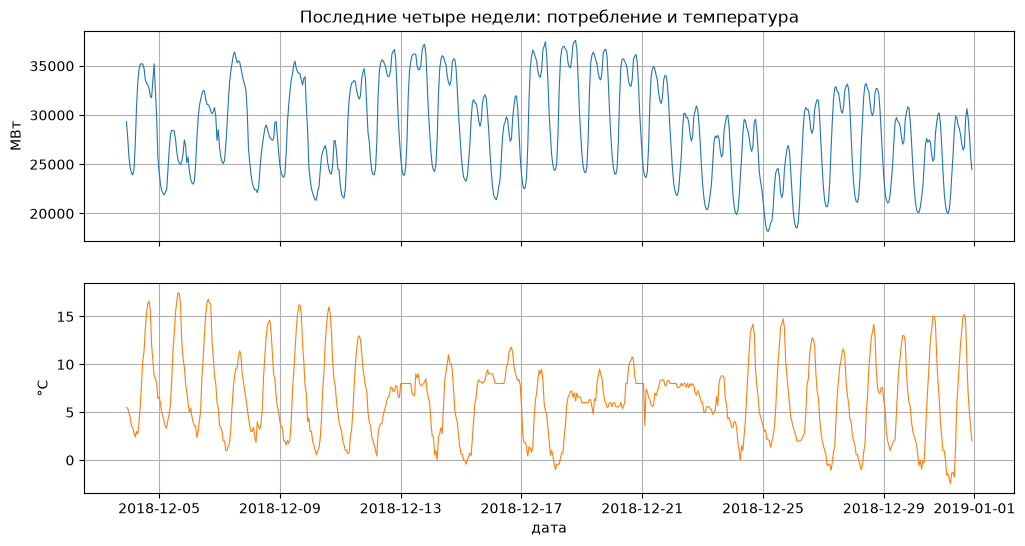

In [5]:
last_weeks = Y_df[Y_df["ds"] >= Y_df["ds"].max() - pd.Timedelta(days=28)]
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(last_weeks["ds"], last_weeks["y"], lw=0.8, color="tab:blue")
axes[0].set(ylabel="МВт", title="Последние четыре недели: потребление и температура")
axes[1].plot(last_weeks["ds"], last_weeks["temp"], lw=0.8, color="tab:orange")
axes[1].set(ylabel="°C", xlabel="дата");

Нагрузка — суточные качели с просадкой на выходных, температура — медленная волна с суточным ходом.
Признаки должны работать: потребление зависит от часа суток (известен в будущем) и от температуры
(в будущем неизвестна, но сильно автокоррелирована).

## Постановка

Прогноз на сутки вперёд (`h=24`) по неделе истории (`input_size=168`), три окна с шагом `h`. Горизонт короткий
и это принципиально: TFT проектировался под многошаговые прогнозы, на которых известные в будущем признаки
успевают окупиться. Бюджет обучения — как в 12.1: фиксированные `100` шагов для линейных моделей и `300`
для трансформеров.

In [6]:
H, L, N_WINDOWS, LR = 24, 168, 3, 1e-3
LINEAR_STEPS, TRANSFORMER_STEPS = 100, 300

HIST = ["temp"]  # исторические: известны только в прошлом
FUTR = ["hour", "dayofweek", "month", "is_weekend"]  # известные в будущем: вычисляются из даты

common = dict(h=H, input_size=L, learning_rate=LR, random_seed=SEED, **TRAINER_KW)
linear_kw = {**common, "max_steps": LINEAR_STEPS}
transformer_kw = {**common, "max_steps": TRANSFORMER_STEPS}

## Признаки: три типа

TFT разводит входы по **доступности в момент прогноза**. Это единственная классификация, которая имеет
значение: от неё зависит, что вообще можно подать в модель.

| тип | когда известно | пример здесь | пример из жизни |
|---|---|---|---|
| статические | всегда, для всего ряда | — | город, тип здания, категория товара |
| исторические | только до момента прогноза | `temp` | продажи, цена, число визитов |
| известные в будущем | на всём горизонте | `hour`, `dayofweek`, `month`, `is_weekend` | праздники, промо-план, календарь |

Главный вопрос к любому признаку: **будет ли его значение известно, когда мы строим прогноз?** Если нет —
это либо исторический признак, либо утечка. Будущая температура в момент прогноза неизвестна: прогноз погоды
на неделю вперёд — отдельная задача.

Статических признаков у нас нет: ряд один. В neuralforecast они передаются отдельной таблицей `static_df`
и списком `stat_exog_list`.

## Планка

`SeasonalNaive` с периодом 24 повторяет вчерашний день, с периодом 168 — прошлую неделю. Для почасового
потребления это сильные бейзлайны: недельный профиль устойчивее суточного.

In [7]:
sf = StatsForecast(
    models=[SeasonalNaive(season_length=24, alias="SN 24"), SeasonalNaive(season_length=168, alias="SN 168")],
    freq="h",
)
cv_base = sf.cross_validation(df=Y_df[["unique_id", "ds", "y"]], h=H, n_windows=N_WINDOWS, step_size=H)
score(cv_base)

metric,mae,mape
SN 168,420.306,0.0165
SN 24,1664.778,0.0629


Две нейросетевые планки без признаков: линейная модель и канально-независимый трансформер с патчами.
Обе не читают ковариаты вовсе — это точка сравнения для TFT.

In [8]:
t0 = time.time()
nf_dl = NeuralForecast(models=[DLinear(alias="DLinear", **linear_kw)], freq="h")
cv_dl = nf_dl.cross_validation(df=Y_df, n_windows=N_WINDOWS, step_size=H)
time_dl = time.time() - t0
score(cv_dl)

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Predicting: |          | 0/? [00:00<?, ?it/s]

metric,mae,mape
DLinear,1253.408,0.0499


In [9]:
t0 = time.time()
nf_pt = NeuralForecast(models=[PatchTST(alias="PatchTST", **transformer_kw)], freq="h")
cv_pt = nf_pt.cross_validation(df=Y_df, n_windows=N_WINDOWS, step_size=H)
time_pt = time.time() - t0
score(cv_pt)

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Predicting: |          | 0/? [00:00<?, ?it/s]

metric,mae,mape
PatchTST,1421.659,0.0543


## Устройство TFT

Схема целиком. Верхний ряд — от входов до рекуррентных слоёв, нижний — от обогащения статикой до выхода.

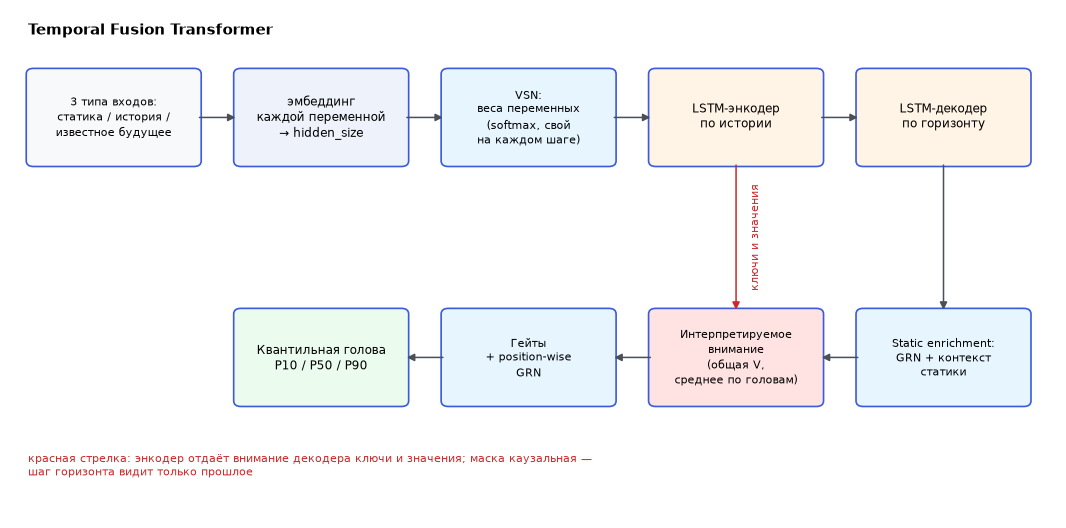

In [10]:
fig, ax = plt.subplots(figsize=(13.5, 6.6))
ax.set(xlim=(0, 11.6), ylim=(0, 7.2))
ax.axis("off")

Y1, Y2, HB, W = 5.0, 1.6, 1.35, 1.9
xs = [0.2, 2.5, 4.8, 7.1, 9.4]

box(ax, xs[0], Y1, W, HB, "3 типа входов:\nстатика / история /\nизвестное будущее", fc="#f8f9fa", fs=8)
box(ax, xs[1], Y1, W, HB, "эмбеддинг\nкаждой переменной\n→ hidden_size", fs=8.5)
box(ax, xs[2], Y1, W, HB, "VSN:\nвеса переменных\n(softmax, свой\nна каждом шаге)", fc="#e7f5ff", fs=8)
box(ax, xs[3], Y1, W, HB, "LSTM-энкодер\nпо истории", fc="#fff4e6", fs=8.5)
box(ax, xs[4], Y1, W, HB, "LSTM-декодер\nпо горизонту", fc="#fff4e6", fs=8.5)
for i in range(4):
    arrow(ax, (xs[i] + W, Y1 + HB / 2), (xs[i + 1], Y1 + HB / 2))

box(ax, xs[4], Y2, W, HB, "Static enrichment:\nGRN + контекст\nстатики", fc="#e7f5ff", fs=8)
box(ax, xs[3], Y2, W, HB, "Интерпретируемое\nвнимание\n(общая V,\nсреднее по головам)", fc="#ffe3e3", fs=8)
box(ax, xs[2], Y2, W, HB, "Гейты\n+ position-wise\nGRN", fc="#e7f5ff", fs=8)
box(ax, xs[1], Y2, W, HB, "Квантильная голова\nP10 / P50 / P90", fc="#ebfbee", fs=8.5)

arrow(ax, (xs[4] + W / 2, Y1), (xs[4] + W / 2, Y2 + HB))
arrow(ax, (xs[4], Y2 + HB / 2), (xs[3] + W, Y2 + HB / 2))
arrow(ax, (xs[3], Y2 + HB / 2), (xs[2] + W, Y2 + HB / 2))
arrow(ax, (xs[2], Y2 + HB / 2), (xs[1] + W, Y2 + HB / 2))

arrow(ax, (xs[3] + W / 2, Y1), (xs[3] + W / 2, Y2 + HB), color="#c92a2a")
ax.text(xs[3] + W / 2 + 0.15, (Y1 + Y2 + HB) / 2, "ключи и значения", color="#c92a2a", fontsize=8, rotation=90, va="center")

ax.text(0.2, 6.85, "Temporal Fusion Transformer", fontsize=11, fontweight="bold")
ax.text(0.2, 0.55, "красная стрелка: энкодер отдаёт внимание декодера ключи и значения; маска каузальная —\n"
        "шаг горизонта видит только прошлое", fontsize=8, color="#c92a2a", va="bottom");

**GRN** стоит всюду, где в обычном трансформере полносвязный слой. Это линейный слой с гейтом и
остаточной связью:

$$\mathrm{GRN}_\omega(a) = \mathrm{LayerNorm}\big(a + \mathrm{GLU}_\omega(\eta_1)\big),\qquad
\eta_1 = W_1 a + b_1,$$
$$\mathrm{GLU}_\omega(\eta_1) = \sigma(W_2 \eta_1 + b_2) \odot (W_3 \eta_1 + b_3).$$

Сигмоида $\sigma$ решает, какая доля каждой компоненты проходит дальше. Если гейт закрыт, блок превращается
в тождественное отображение — модель сама выбирает, сколько нелинейности нужно в этом месте.

**Отбор переменных (VSN).** Все векторы одного типа склеиваются в матрицу $\Xi_t$, прогоняются через GRN,
и softmax по переменным даёт веса:

$$v_{\chi,t} = \mathrm{softmax}\big(\mathrm{GRN}_v(\Xi_t, c_s)\big)_\chi,\qquad
\tilde{\xi}_t = \sum_\chi v_{\chi,t}\,\tilde{\xi}_t^{(\chi)} .$$

$c_s$ — контекст статики. Веса пересчитываются на каждом шаге времени: в час пик модель может опираться
на температуру, ночью — на час суток.

**LSTM-энкодер и декодер** вносят порядок. Внимание порядок не знает, поэтому последовательность сначала
проходит через рекуррентный слой — он играет роль позиционного кодирования и извлекает локальные паттерны.

**Интерпретируемое внимание.** Один слой, каузальная маска. Отличие от обычного multi-head: матрица значений
$V$ **общая для всех голов**, а выходы голов усредняются, а не склеиваются:

$$\tilde H = \frac{1}{m}\sum_{h=1}^{m} A_h\, V W_V,\qquad A_h = \mathrm{softmax}\!\left(\frac{Q_h K_h^\top}{\sqrt{d_k}}\right).$$

Поэтому веса можно усреднить по головам и получить одну осмысленную карту.

**Выход.** Линейная голова `hidden_size → 1` (или на число квантилей) на каждом шаге горизонта.

## TFT без признаков

Точка отсчёта: TFT с пустыми списками признаков. Он видит только собственный ряд, но сохраняет всю машинерию —
GRN, LSTM, внимание.

In [11]:
t0 = time.time()
nf_tft0 = NeuralForecast(models=[TFT(alias="TFT без признаков", **transformer_kw)], freq="h")
cv_tft0 = nf_tft0.cross_validation(df=Y_df, n_windows=N_WINDOWS, step_size=H)
time_tft0 = time.time() - t0
score(cv_tft0)

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Predicting: |          | 0/? [00:00<?, ?it/s]

metric,mae,mape
TFT без признаков,1394.268,0.0527


## TFT с признаками

Те же архитектура и бюджет, меняются только `hist_exog_list` и `futr_exog_list`.

In [12]:
t0 = time.time()
nf_tft = NeuralForecast(
    models=[TFT(alias="TFT + признаки", hist_exog_list=HIST, futr_exog_list=FUTR, **transformer_kw)], freq="h"
)
cv_tft = nf_tft.cross_validation(df=Y_df, n_windows=N_WINDOWS, step_size=H)
time_tft = time.time() - t0
score(cv_tft)

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Predicting: |          | 0/? [00:00<?, ?it/s]

metric,mae,mape
TFT + признаки,1588.062,0.0592


In [13]:
summary = pd.concat([score(cv_base), score(cv_dl), score(cv_pt), score(cv_tft0), score(cv_tft)]).sort_values("mae")
summary["параметров"] = summary.index.map(
    {
        "DLinear": n_params(nf_dl.models[0]),
        "PatchTST": n_params(nf_pt.models[0]),
        "TFT без признаков": n_params(nf_tft0.models[0]),
        "TFT + признаки": n_params(nf_tft.models[0]),
    }
)
summary["обучение, с"] = summary.index.map(
    {"DLinear": time_dl, "PatchTST": time_pt, "TFT без признаков": time_tft0, "TFT + признаки": time_tft}
)
summary.round(2)

metric,mae,mape,параметров,"обучение, с"
SN 168,420.31,0.02,NaN,NaN
DLinear,1253.41,0.05,8112.0,1.82
TFT без признаков,1394.27,0.05,870158.0,30.30
PatchTST,1421.66,0.05,466843.0,7.36
TFT + признаки,1588.06,0.06,1457843.0,47.58
SN 24,1664.78,0.06,NaN,NaN


Три сравнения в одной таблице.

**Планка против сетей.** Наивная модель с недельным периодом должна остаться лучшей или близкой к лучшей:
суточный профиль здесь устойчив, и сети на одном ряду в 35 тысяч точек не успевают выучить масштаб в 25–40
тысяч МВт. Именно поэтому планку из наивных моделей ставят всегда.

**TFT против DLinear.** У TFT в сотни раз больше параметров (тысячи против миллиона). Если он не обходит линейную модель,
это нормально: в статье TFT сравнивали с ARIMA, ETS, DeepAR и seq2seq с подбором гиперпараметров под каждый
набор, и выигрывал он на своей задаче, а не всегда.

**С признаками против без признаков.** Одна архитектура, один бюджет, разные входы. Разница между двумя
строками TFT — это и есть цена признаков. Обратите внимание на цену в параметрах: пять признаков увеличивают
модель примерно на две трети, потому что каждая переменная получает свой эмбеддинг и свой GRN.

## Важность переменных

Веса VSN — ответ на вопрос «на что модель смотрит», отдельно на каждом шаге времени. В neuralforecast они
сохраняются после предсказания и достаются штатным методом.

Чтобы их достать, нужен прогноз, а прогноз с признаками упирается в тот же вопрос про доступность: календарь
на сутки вперёд надо посчитать и передать отдельной таблицей `futr_df`. Температуру на горизонт взять негде —
поэтому она исторический признак.

In [14]:
cutoff = cv_tft["cutoff"].max()
history = Y_df[Y_df["ds"] <= cutoff]

futr_df = nf_tft.make_future_dataframe(df=history, h=H)
futr_df["hour"] = futr_df["ds"].dt.hour
futr_df["dayofweek"] = futr_df["ds"].dt.dayofweek
futr_df["month"] = futr_df["ds"].dt.month
futr_df["is_weekend"] = (futr_df["dayofweek"] >= 5).astype(int)

_ = nf_tft.predict(df=history, futr_df=futr_df)

model_tft = nf_tft.models[0]
imp = model_tft.feature_importances()
print("доступные интерпретации:", list(imp))

past = imp["Past variable importance over time"]
print("колонки:", list(past.columns), "| строк:", len(past))

Predicting: |          | 0/? [00:00<?, ?it/s]

доступные интерпретации: ['Past variable importance over time', 'Future variable importance over time']
колонки: ['temp', 'hour', 'dayofweek', 'month', 'is_weekend', 'observed_target'] | строк: 168


In [15]:
means = past.mean().sort_values(ascending=False).to_frame("средний вес")
means["кратно равномерному"] = (means["средний вес"] * len(means)).round(2)
means.round(3)

,средний вес,кратно равномерному
observed_target,0.286,1.71
dayofweek,0.198,1.19
hour,0.187,1.12
temp,0.145,0.87
is_weekend,0.095,0.57
month,0.089,0.54


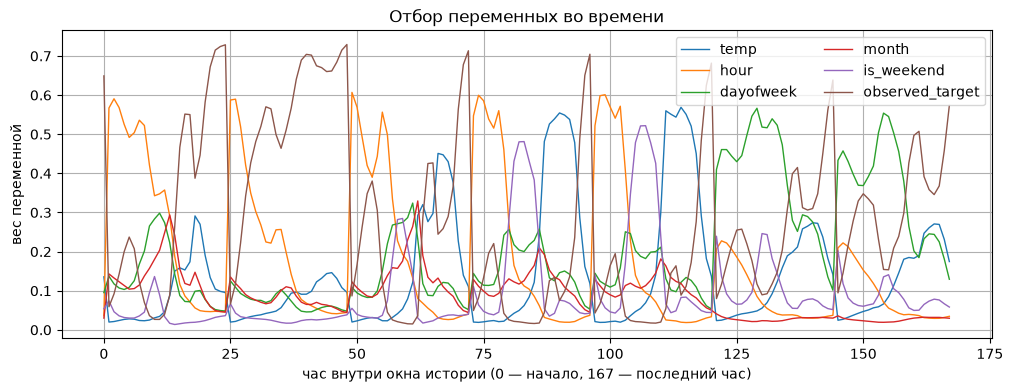

In [16]:
fig, ax = plt.subplots(figsize=(12, 4))
for col in past.columns:
    ax.plot(past[col].to_numpy(), lw=1, label=col)
ax.set(xlabel="час внутри окна истории (0 — начало, 167 — последний час)", ylabel="вес переменной",
       title="Отбор переменных во времени");
ax.legend(ncol=2);

Смотреть надо на две разные вещи.

**Средние веса.** Веса нормированы softmax, их шесть, значит при полном безразличии каждый получил бы 0.167.
Вторая колонка показывает отклонение от этого уровня. Выраженного фаворита у модели нет: распределение плоское.
Температура, которой на горизонте не будет, всё равно держит заметный вес — и это работает, потому что она
сильно автокоррелирована: последний час окна хорошо предсказывает ближайшие сутки. Месяц, который внутри
окна в 168 часов почти не меняется, оказывается последним.

**Кривые по времени.** На каждом шаге окна один-два признака забирают почти всё: кривые скачут от 0.05
до 0.7, доминирующая переменная меняется несколько раз внутри окна. Мгновенный вес втрое-впятеро больше
своего среднего — норма, а не выброс.

В этом и смысл VSN: не «модель считает температуру важной на 16%», а «модель решает заново на каждом шаге».
Средние веса — удобная сводка, но она описывает модель, которой не существует.

Оговорка: **вес переменной — не вклад в прогноз.** Переменная с маленьким весом всё равно проходит через
свой GRN и может влиять на выход, а веса, нормированные в сумму единицу, всегда выглядят значимыми.
Доказательство важности — абляция, а не вес.

## Внимание как функция лага

Вторая интерпретация: усреднённая матрица внимания показывает, насколько далеко назад модель смотрит.
Ось — расстояние между запросом и ключом в часах.

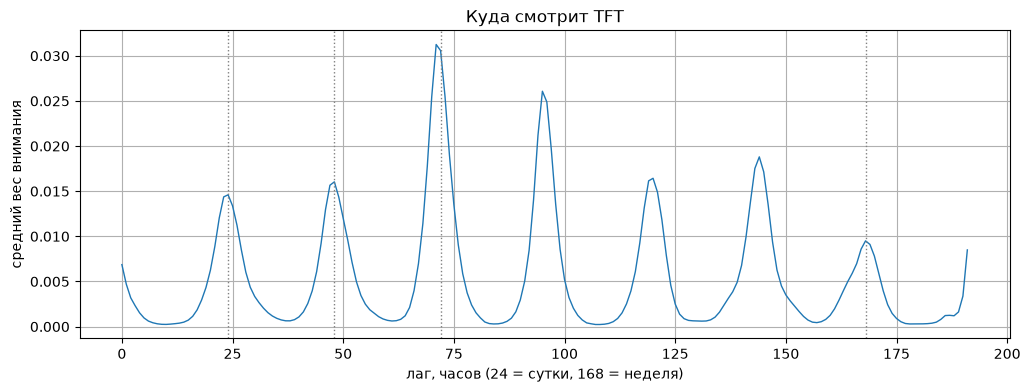

In [17]:
def attention_by_lag(model):
    """Средний вес внимания по расстоянию «запрос − ключ» в часах."""
    w = model.interpretability_params["attn_wts"].mean(dim=(0, 1)).cpu().numpy()  # [шаги, шаги]
    dec = w[-model.h :, :]  # только запросы декодера: они и делают горизонт
    queries = np.arange(model.h) + model.input_size  # абсолютные позиции запросов
    keys = np.arange(w.shape[1])  # абсолютные позиции ключей
    distance = queries[:, None] - keys[None, :]  # каузальная маска даёт только >= 0
    return np.array([dec[distance == lag].mean() for lag in range(distance.max() + 1)])


lag_curve = attention_by_lag(model_tft)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(lag_curve, lw=1)
for lag in (24, 48, 72, 168):
    ax.axvline(lag, color="grey", ls=":", lw=1)
ax.set(xlabel="лаг, часов (24 = сутки, 168 = неделя)", ylabel="средний вес внимания",
       title="Куда смотрит TFT");

Пики стоят на 24, 48, 72, 96, 120, 144 и 168 часах: модель смотрит на те же часы предыдущих суток и на тот же
час неделю назад. Провалы между пиками примерно в десять раз ниже. Взлёт у правого края — артефакт усреднения:
на лаге 191 остаётся ровно одна пара позиций, и среднее по ней шумит.

Три ограничения, без которых это читать нельзя.

**Внимание считается не над наблюдениями.** Оно работает над выходами LSTM и обогащёнными признаками:
«внимание к лагу 24» — это внимание к сглаженному рекуррентным слоем состоянию, а не к конкретному значению
сутки назад. Позиционную работу делает LSTM, а не внимание.

**Вес — не вклад.** Одна и та же функция выхода получается с разными матрицами весов; на наивном трансформере
три инициализации давали одинаковую ошибку и несопоставимые карты.

**Усреднение по запросам стирает структуру.** Мы смотрим на среднее по 24 запросам горизонта; если модель
смотрит на разные лаги для разных шагов, средняя кривая этого не покажет.

## Квантили

Интервал задаётся не архитектурой, а **функцией потерь**: та же TFT с `MQLoss` получает голову на несколько
квантилей вместо одной.

Проверять интервалы надо двумя числами: покрытием (доля фактов внутри) и квантильной потерей (pinball).
Одно без другого бессмысленно: интервал можно растянуть на всю ось и получить 100% покрытия.

In [18]:
t0 = time.time()
nf_q = NeuralForecast(
    models=[
        TFT(
            alias="TFT",
            loss=MQLoss(level=[80, 90]),
            hist_exog_list=HIST,
            futr_exog_list=FUTR,
            **transformer_kw,
        )
    ],
    freq="h",
)
cv_q = nf_q.cross_validation(df=Y_df, n_windows=N_WINDOWS, step_size=H)
time_q = time.time() - t0
print("колонки:", list(cv_q.columns))

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Predicting: |          | 0/? [00:00<?, ?it/s]

колонки: ['unique_id', 'ds', 'cutoff', 'TFT-median', 'TFT-lo-90', 'TFT-lo-80', 'TFT-hi-80', 'TFT-hi-90', 'y']


In [19]:
def pinball(y, y_hat, tau):
    """Квантильная потеря: перекос штрафа в зависимости от стороны ошибки."""
    d = y - y_hat
    return np.maximum(tau * d, (tau - 1) * d).mean()


rows = {}
for level in (80, 90):
    lo, hi = f"TFT-lo-{level}", f"TFT-hi-{level}"
    tau = (100 - level) / 200  # нижний квантиль: 0.1 для 80%, 0.05 для 90%
    rows[level] = {
        "покрытие, %": 100 * ((cv_q[lo] <= cv_q["y"]) & (cv_q["y"] <= cv_q[hi])).mean(),
        "pinball, нижний": pinball(cv_q["y"], cv_q[lo], tau),
        "pinball, верхний": pinball(cv_q["y"], cv_q[hi], 1 - tau),
    }
pd.DataFrame(rows).T.round(3)

,"покрытие, %","pinball, нижний","pinball, верхний"
80,79.167,445.598,341.638
90,86.111,231.709,212.473


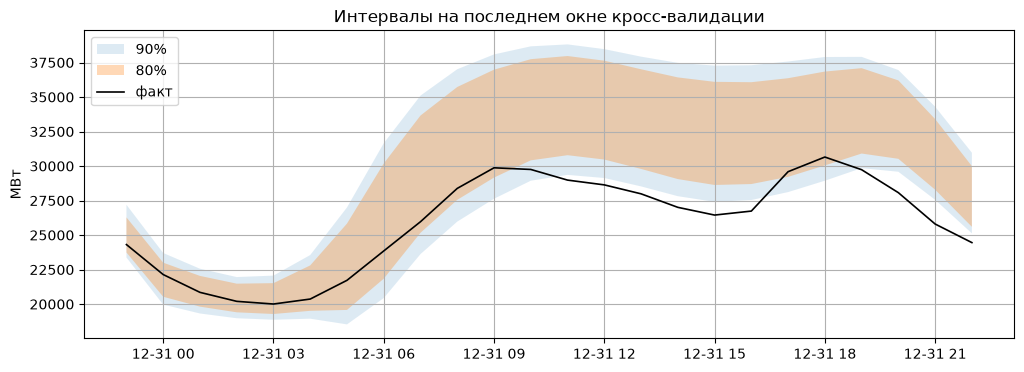

In [20]:
last = cv_q[cv_q["cutoff"] == cv_q["cutoff"].max()].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(12, 4))
ax.fill_between(last["ds"], last["TFT-lo-90"], last["TFT-hi-90"], alpha=0.15, label="90%")
ax.fill_between(last["ds"], last["TFT-lo-80"], last["TFT-hi-80"], alpha=0.3, label="80%")
ax.plot(last["ds"], last["y"], color="black", lw=1.2, label="факт")
ax.set(ylabel="МВт", title="Интервалы на последнем окне кросс-валидации");
ax.legend();

Покрытие надо сравнивать с номиналом с поправкой на размер выборки. Точек всего 72: три окна по 24 шага.
У доли покрытия выборочная ошибка $\sqrt{p(1-p)/n}$ — при $p=0.8$ и $n=72$ это 4.7 процентного пункта,
при $p=0.9$ — 3.5. Отклонения в пределах одной сигмы неотличимы от идеальной калибровки, и заявить большее
по 72 точкам нельзя: нужны десятки окон.

Второе число — pinball. Сравнивать его между уровнями бессмысленно: у 80% и 90% разные квантили, поэтому
и потери разные по построению. Сравнивать можно только между моделями на одном уровне.

Это и есть ответ на вопрос «откуда у нейросети интервал»: из функции потерь, которая штрафует за каждую
сторону ошибки по-разному. Тот же приём работал бы на любой модели из предыдущих ноутбуков — достаточно
поменять `loss`.

## Что TFT умеет и чего не умеет

Умеет три вещи, которых нет у предыдущих моделей:

1. **Разные типы признаков.** Статика, история и известное будущее разведены по разным энкодерам.
2. **Видимый отбор переменных.** Веса VSN пересчитываются на каждом шаге и читаются из модели — с оговоркой,
   что вес не равен вкладу.
3. **Интервалы.** Через квантильную голову и соответствующую функцию потерь.

Не умеет главного: **быстро обучаться на маленьких данных**. Параметров у неё сотни тысяч, и на одном ряду
это скорее недостаток. В абляции статьи наибольший вклад дают LSTM и self-attention, причём соотношение
между ними меняется от набора к набору: на Electricity локальная обработка почти не нужна, там важнее
внимание. Заранее по свойствам данных это не угадывается.

### Для самостоятельного изучения

- **`n_rnn_layers` и `rnn_type`.** Второй слой LSTM и замена на GRU: сколько из того, что делает TFT,
  относится к рекуррентной части, а не к вниманию.
- **`one_rnn_initial_state`.** Один начальный вектор из статики на все слои вместо отдельного на каждый.
- **Абляция внимания.** Подменить модуль внимания на тождественное отображение до обучения. В статье замена
  внимания стоит больше 20% медианной квантильной потери.
- **Больше признаков.** В датасете есть выработка по типам (ветер, солнце, гидро) и прогноз выработки
  на сутки вперёд — настоящие известные в будущем признаки, сильнее календаря.
- **Другие города.** Погода по пяти городам как пять исторических признаков против одного Мадрида.
- **Три сида.** Разница `TFT + признаки` и `TFT без признаков` должна быть больше разброса по инициализациям.
- **Детекция режимов.** Третья интерпретация из статьи: расстояние между текущей матрицей внимания и средней
  по выборке как индикатор смены режима.

## Итоги

TFT — не «лучший трансформер», а система под прикладную задачу: разнотипные входы, отбор переменных,
интервалы, интерпретация. Внимание в ней один из компонентов, и статью стоит читать не как «вот как надо
делать внимание», а как «вот как выглядит модель, которую можно поставить на поток».

Три идеи недели собраны вместе: скалярный токен оказался слабым входом, отказ от внимания не ухудшил
результат, а превращение модели в систему подготовки признаков дало то, чего не давала ни одна архитектура
сама по себе.

Дальше — свести всё в одну таблицу на одних окнах и решить, что выбирать под какую задачу.